# Middlesex County Prosecution Analysis

**Source:** Middlesex DA charge extract, 8 yearly sheets (2017 to 2024), cleaned in `eda_middlesex_2017_2024.ipynb`
**Study period:** 2017 to 2024 (year of Earliest Event Date; the extract has no filing date)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge (felony over misdemeanor, then statutory class).
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

**Middlesex scope:** Motor Vehicle Other cases and civil-infraction charges are removed (criminal MV cases are kept: OUI, OUI serious bodily injury, MV homicide, MV serious bodily injury). See section 3.5 of the EDA.

## Setup

In [1]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)

set_style()

COUNTY = "middlesex"
YEARS = range(2017, 2025)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
- `clean/charges.csv` (from `eda_middlesex_2017_2024.ipynb`): one row per charge, duplicates removed, Motor Vehicle Other cases and civil charges dropped. It includes open cases, so the same file is used as the **filed** extract (volume, per capita, prior record) and the **disposed** extract (outcomes, sentencing, time, disparities).
- `population.csv`: Census July 1 county population estimates.

Middlesex has no filing date, so **Earliest Event Date** (first court event) is used, and each case's year is its sheet year, which equals the year of Earliest Event Date.

In [2]:
DATA_DIR = os.path.join(repo_root, "fa26", "data", "middlesex")
FILED_PATH = os.path.join(DATA_DIR, "clean", "charges.csv")   # includes open cases
DISPOSED_PATH = FILED_PATH                                    # single extract
POP_PATH = os.path.join(DATA_DIR, "population.csv")

def read_any(path):
    return pd.read_csv(path, dtype=str)   # read as text so IDs aren't converted

COLS = {
    "docket_number":    "Case Number",           # one defendant per case number
    "defendant_id":     "Defendant ID",
    "charge_count":     "Criminal Count Number",
    "filing_date":      "Earliest Event Date",   # no filing date in the extract
    "disposition_date": "Disposition Date",
    "disposition":      "Imposed Disposition",
    "charge_level":     None,                    # no felony/misdemeanor field; lead charge used instead
    "offense_category": "offense_group",         # Charge/ Crime Type mapped to shared groups (below)
    "court":            "Court Location",
    "race":             "race_eth",              # race + ethnicity combined (below)
    "sex":              "sex_std",               # Defendant Gender, Not Provided -> missing
    "sentence_type":    "Sentence Type Imposed",
}

### Middlesex-specific fields
Three shared fields have to be derived before standardizing:
- **Race/ethnicity:** Hispanic/Latino is recorded under `Defendant Ethnicity` and almost never under `Defendant Race`. So a defendant is **Hispanic** if either field says Hispanic/Latino; otherwise the race field is used. "Not Provided", "Unknown" and "Other/Unknown" count as missing.
- **Sex:** Male / Female; "Not Provided" and "Unknown" count as missing.
- **Offense group:** the 92 `Charge/ Crime Type` values are mapped onto the 15 offense groups Worcester and Plymouth use, so offense charts line up across counties. Crime type is recorded once per case, so every charge in a case has the same group.

In [3]:
RACE_MAP = {
    "White": "White",
    "Black or African American": "Black",
    "Asian": "Asian",
    "American Indian/Alaska Native": "American Indian",
    "Native Hawaiian/Pacific Islander": "Pacific Islander",
    # Not Provided, Unknown, Other/Unknown, blank -> missing (Unknown)
}
SEX_MAP = {"Male": "Male", "Female": "Female"}

OFFENSE_GROUPS = {
    "Assault & Battery": ["Physical Assault", "Threats", "Criminal Harassment", "Stalking"],
    "Assault w/ Weapon": ["Physical Assault with a Weapon"],
    "Breaking & Entering": ["Breaking and Entering/Building", "Breaking and Entering/MV-Boat",
                            "Breaking and Entering/Dwelling", "Burglary/Unarmed", "Burglary/Armed",
                            "Home Invasion", "Home Invasion with Weapon"],
    "Disorderly/Public Order": ["Public Order/Other", "Public Policy Other", "OFFENSIVE BEHAVIOR",
                                "Prostitution", "Animals", "Licensing/Regulatory", "Gaming",
                                "CODE VIOLATIONS", "Environmental", "Fire/Bomb/Threat"],
    "Domestic Violence": ["Violation of Restraining Order", "Domestic Violence/Physical Assault",
                          "Domestic Violence/Violation Rest. Order", "Domestic Violence/Weapon"],
    "Drug Distribution": ["Drugs/Distribution/Possession with Intent", "Drugs/Trafficking",
                          "Drugs/Distribution/Possession w Intent/School Zone", "Drugs/Trafficking/School Zone"],
    "Drug Possession": ["Drugs/Possession", "DRUGS/POSSESSION", "NARCOTICS"],
    "Firearms/Weapons": ["Firearms", "Large Capacity", "Dangerous Weapons", "Ammunition",
                         "BB Gun/ Pellet Gun/ Air Gun", "Explosives"],
    "Fraud/Forgery": ["Fraud", "Embezzlement", "Financial Exploitation", "Computer", "Computer/White Collar"],
    "Larceny/Theft": ["Larceny Other", "Larceny from Building", "Larceny from MV-Boat", "Larceny from Person",
                      "Larceny from Home", "LARCENY", "Larceny from Public Official", "Larceny MV"],
    "OUI/DUI": ["Motor Vehicle OUI", "Motor Vehicle OUI Serious Bodily Injury"],
    "Property Damage": ["Destruction of Property", "Arson"],
    "Robbery": ["Robbery/Armed", "Robbery/Unarmed", "Carjacking"],
    "Sexual Offenses": ["Indecent Over 14", "Indecent Under 14", "Sexual Assault", "Rape",
                        "Assault with Intent to Rape", "Open and Gross", "Lewd", "Pornography",
                        "Failure to Register/Sex Offender", "Sexually Dangerous Person", "Child Abuse/Sexual"],
    # Everything else (homicide, kidnapping, MV homicide/SBI, fugitive, failure to appear,
    # witness intimidation, conspiracy, attempt, accessory, ...) -> Other/Unknown
}
CRIME_TO_GROUP = {crime: grp for grp, crimes in OFFENSE_GROUPS.items() for crime in crimes}


def add_derived(raw):
    raw = raw.copy()
    hispanic = raw["Defendant Ethnicity"].eq("Hispanic/Latino") | raw["Defendant Race"].eq("Hispanic/Latino")
    raw["race_eth"] = raw["Defendant Race"].map(RACE_MAP).mask(hispanic, "Hispanic")
    raw["sex_std"] = raw["Defendant Gender"].map(SEX_MAP)
    raw["offense_group"] = raw["Charge/ Crime Type"].map(CRIME_TO_GROUP).fillna("Other/Unknown")
    return raw


def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    out = raw.rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = pd.Series(np.nan, index=out.index, dtype="object")
    out["case_key"] = out["docket_number"].astype(str) + "_" + out["defendant_id"].astype(str)
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out["disposition_date"] = pd.to_datetime(out["disposition_date"], errors="coerce")
    out["filing_year"] = out["sheet_year"].astype(int)   # = year of Earliest Event Date
    return out


filed_raw = add_derived(read_any(FILED_PATH))
filed = standardize(filed_raw)
disposed = filed.copy()   # single extract; open charges become Pending below

missing_cols = [k for k, v in COLS.items() if v is None or v not in filed_raw.columns]
print("Not available in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")

unmapped = sorted(set(filed_raw["Charge/ Crime Type"].dropna()) - set(CRIME_TO_GROUP))
print(f"\nCrime types in Other/Unknown ({len(unmapped)}):", ", ".join(unmapped))

Not available in extract: ['charge_level']
Filed: 223,071 charges, 111,602 cases
Disposed: 223,071 charges, 111,602 cases

Crime types in Other/Unknown (22): Accessory After the Fact, Accessory Before the Fact, Attempt to Commit a Crime, Civil Rights, Conspiracy, Contempt, Escape, Failure to Appear, Fugitive, Homicide, Human trafficking, Intimidation of a Witness, Involuntary Manslaughter, Kidnapping, Motor Vehicle Homicide, Motor Vehicle Serious Bodily Injury, Murder 1st degree, Murder 2nd degree, Perjury, Unsolved Homicide, Voluntary Manslaughter, Wiretapping


In [4]:
# Offense groups: cases per group (crime type is the same on every charge of a case)
first_charge = filed.drop_duplicates("case_key")
(first_charge.groupby(["offense_category", "Charge/ Crime Type"]).size()
   .rename("cases").reset_index()
   .sort_values(["offense_category", "cases"], ascending=[True, False])
   .set_index(["offense_category", "Charge/ Crime Type"]))

cases
offense_category  Charge/ Crime Type                   
Assault & Battery Physical Assault                28146
                  Threats                          1369
                  Criminal Harassment               342
                  Stalking                          125
Assault w/ Weapon Physical Assault with a Weapon   9919
...                                                 ...
Sexual Offenses   Lewd                               90
                  Indecent Under 14                  85
                  Assault with Intent to Rape        47
                  Sexually Dangerous Person          26
                  Child Abuse/Sexual                  3

[92 rows x 1 columns]

## Map Dispositions and Exclusions
Every disposition is mapped onto the shared buckets:
**Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**, plus **Pending** for open charges.
Nolle prosequi counts as Dismissal. Unmapped values fall into Other, so check that the Other share is small.

Middlesex has ~70 raw dispositions, so they are mapped by rule. The full raw → bucket table is printed below.
- A charge with **no disposition** is **Pending** if its case is Open or in Default (waiting on a warrant), **Other** if the case was Transferred, and **Unknown** otherwise.

In [5]:
disposed["disposition"].value_counts(dropna=False).head(40)

disposition
DISMISSED W/O PREJUDICE LACK OF PROSECUTION           41650
GUILTY CHANGE OF PLEA                                 31577
NaN                                                   23514
CONTINUED W/O FINDING                                 23370
NOLLE PROSEQUI                                        22537
DISMISSED W/O  PREJUDICE                              19408
DISMISSED OUTRIGHT AT REQUEST OF CW (POST-ARR)        17915
PRE-TRIAL PROBATION                                   13544
NOT GUILTY TRIAL                                       4035
DISMISSED OUTRIGHT AT REQUEST OF CW (PRIOR TO ARR)     3275
DISMISSED ON COURT COSTS                               3004
MOTION TO DISMISS ALLOWED                              2237
DISMISSED BY COURT (POST-ARRAIGNMENT)                  2112
GUILTY TRIAL                                           1630
DISMISSED BY FINES                                     1520
NOT GUILTY JURY TRIAL                                  1277
GUILTY FILED                

In [6]:
def middlesex_outcome(disp, status):
    if pd.isna(disp):
        if status in ("Open", "Default"):
            return "Pending"
        return "Other" if status == "Transferred" else None    # None -> Unknown
    d = disp.upper()
    if d.startswith(("NOT GUILTY", "NOT DELINQUENT")):
        return "Acquittal"
    if d.startswith(("NO BILL", "NO PROBABLE CAUSE")):        # grand jury / probable cause declined
        return "Dismissal"
    if d.startswith(("CWOF", "CONTINUED W/O FINDING")):
        return "CWOF"
    if d.startswith(("PRE-TRIAL PROBATION", "DIVERSION", "FILED WITHOUT CHANGE OF PLEA")):
        return "Diversion"
    if ("GUILTY" in d or "DELINQUENT" in d) and "TRIAL" in d:
        return "Trial Conviction"
    if "GUILTY" in d or "DELINQUENT" in d:                     # change of plea, filed, fines
        return "Plea"
    if d.startswith("NOLLE") or "DISMISS" in d:                # incl. dismissed on costs/fines/restitution
        return "Dismissal"
    return "Other"   # transferred, remanded, bound over, hung jury, mistrial, SDP, general continuance, ...


# Civil infractions and Motor Vehicle Other cases were already removed in the EDA
EXCLUDE_DISPOSITIONS = []
EXCLUDE_OFFENSES = []

disposed["outcome"] = [middlesex_outcome(d, s) for d, s in zip(disposed["disposition"], disposed["Case Status"])]
disposed["outcome"] = disposed["outcome"].map(normalize_outcome)

print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

outcome
Dismissal           116953
Plea                 34440
CWOF                 23565
Pending              22980
Diversion            13908
Acquittal             6967
Trial Conviction      3120
Other                  982
Unknown                156
Name: count, dtype: int64
Share in Other: 0.4%


In [7]:
# Full mapping, for tracing any number back to raw dispositions
(disposed.groupby(["outcome", disposed["disposition"].fillna("(none) / " + disposed["Case Status"].fillna(""))])
   .size().rename("charges").reset_index()
   .sort_values(["outcome", "charges"], ascending=[True, False])
   .set_index(["outcome", "disposition"]))

charges
outcome          disposition                                            
Acquittal        NOT GUILTY TRIAL                                   4035
                 NOT GUILTY JURY TRIAL                              1277
                 NOT GUILTY BENCH TRIAL                              827
                 NOT GUILTY - DIRECTED VERDICT/REQUIRED FINDING      431
                 NOT GUILTY LACK OF CRIMINAL RESPONSIBILITY          217
...                                                                  ...
Trial Conviction GUILTY BENCH TRIAL LESSER INCLUDED                    8
                 Guilty Jury Trial (and Bench) Lesser Included         7
                 DELINQUENT JURY TRIAL                                 5
Unknown          (none) / Closed                                     152
                 (none) / ERROR-INVALID RPT DSPSTN ENTERED             4

[74 rows x 1 columns]

## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [8]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

cov_base = disposed[disposed["filing_year"].isin(YEARS)]   # study period only

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

coverage = pd.DataFrame({
    "pct_missing": [cov_base[f].isna().mean() * 100 for f in COVERAGE_FIELDS],
    "years_available": [years_available(cov_base, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'sentence_type', 'charge_level'}


,pct_missing,years_available,status
docket_number,0.0,2017-2024,ok
defendant_id,0.0,2017-2024,ok
filing_date,0.0,2017-2024,ok
disposition_date,10.6,2017-2024,ok
disposition,10.5,2017-2024,ok
charge_level,100.0,none,insufficient data
offense_category,0.0,2017-2024,ok
court,0.0,2017-2024,ok
race,5.1,2017-2024,ok
sex,0.9,2017-2024,ok


In [9]:
# Race and ethnicity missingness by year (charges)
eth_missing = ~cov_base["Defendant Ethnicity"].isin(["Hispanic/Latino", "Non-Hispanic/Non-Latino", "Non-Hispanic/Latino"])
pd.DataFrame({
    "% race/ethnicity missing": cov_base["race"].isna().groupby(cov_base["filing_year"]).mean() * 100,
    "% ethnicity field missing / Not Provided": eth_missing.groupby(cov_base["filing_year"]).mean() * 100,
}).round(1)

,% race/ethnicity missing,% ethnicity field missing / Not Provided
filing_year,,
2017,14.5,55.6
2018,3.2,32.8
2019,1.9,30.6
2020,2.3,37.8
2021,5.6,35.4
2022,4.1,31.1
2023,3.5,29.9
2024,4.1,30.6


**Notes:**
- Coverage is measured on charges filed 2017 to 2024, open charges included.
- `charge_level` does not exist in Middlesex; cases are classified by lead charge (count 1) instead. Crime type is recorded once per case, so this doesn't change the offense group.
- `disposition` is missing mostly for open and defaulted cases (Pending), not for closed ones.
- `sentence_type` is only filled when a sentence was imposed, so it is checked again in Q4 among **convicted** charges only.
- Race/ethnicity is missing mostly in 2017 (and some 2018). The ethnicity field itself is "Not Provided" or blank for a large share of charges, so **Hispanic is likely undercounted**: defendants with no ethnicity recorded fall back to their race.

## Build Case Table
One row per case, restricted to 2017 to 2024.
- **Unit:** `Case Number` + `Defendant ID`. Each case number has one defendant, so this matches the agreed docket × defendant unit.
- **Most serious charge:** Middlesex has no felony/misdemeanor field, so the **lead charge** (count 1) is used for court, race and sex. Offense group is the same on every charge.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [10]:
LEVEL_RANK = {"Felony": 1, "Misdemeanor": 2}  # no charge_level in Middlesex; all rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].copy()
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    lead = (d.sort_values(["case_key", "level_rank", "charge_count_num"])
              .groupby("case_key").first())
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": d.groupby("case_key")["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": d.groupby("case_key").size(),
    })
    if with_outcome:
        out["outcome"] = d.groupby("case_key")["outcome"].agg(case_outcome)
        out["disposition_date"] = d.groupby("case_key")["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

print(f"Filed cases 2017-2024: {len(filed_cases):,}")
print(f"Disposed cases 2017-2024: {len(cases):,} ({n_pending:,} pending excluded)")

Filed cases 2017-2024: 111,602
Disposed cases 2017-2024: 101,961 (9,641 pending excluded)


## Standardized Case Table
Every chart below is drawn by the shared `county_charts.py` from this one table, so all counties measure the same things the same way and save figures under the same names.

| Column | Definition |
|---|---|
| `year` | year of Earliest Event Date, 2017-2024 |
| `outcome` | most severe outcome across charges (shared buckets); pending cases excluded |
| `offense` | offense group of the case (Charge/ Crime Type mapped to the shared groups) |
| `court`, `race`, `sex` | from the lead charge; Unknown kept |
| `days` | Earliest Event Date to last disposition; missing for negative intervals and EDA date-flagged cases |
| `prior_record` | defendant's cases in the previous 3 years: 0 / 1-2 / 3+ (Unknown if no defendant ID) |

In [11]:
from county_charts import (check_std, prior_record_3yr, plot_volume, plot_per_capita,
                           plot_outcomes, plot_time, plot_time_by_year, rate_table,
                           plot_rates, plot_q8_heatmap, MIN_CELL as STD_MIN_CELL)

vol = filed_cases.groupby("filing_year").size()
vol.index = vol.index.astype(int)

# prior record: all filed (filtered) cases, any year, 3-year lookback
hist = filed.groupby("case_key").agg(person=("defendant_id", "first"),
                                     filing_date=("filing_date", "min"))
prior = prior_record_3yr(hist)

# EDA date flags: offense after Earliest Event Date, or no event date -> no time to disposition
date_flagged = set(filed.loc[filed["date_flag"].notna(), "case_key"])

days = (cases["disposition_date"] - cases["filing_date"]).dt.days
days = days.where((days >= 0) & ~cases["case_key"].isin(date_flagged))
std = pd.DataFrame({
    "case_key": cases["case_key"].values,
    "year": cases["filing_year"].astype(int).values,
    "outcome": cases["outcome"].values,
    "offense": cases["offense_category"].values,
    "court": cases["court"].values,
    "race": cases["race"].values,
    "sex": cases["sex"].values,
    "days": days.values,
})
std["prior_record"] = std["case_key"].map(prior).fillna("Unknown")
std = check_std(std)
print(f"{len(std):,} disposed cases | valid interval: {std['days'].notna().mean():.1%} | "
      f"prior record known: {std['prior_record'].ne('Unknown').mean():.1%}")

101,961 disposed cases | valid interval: 99.3% | prior record known: 100.0%


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

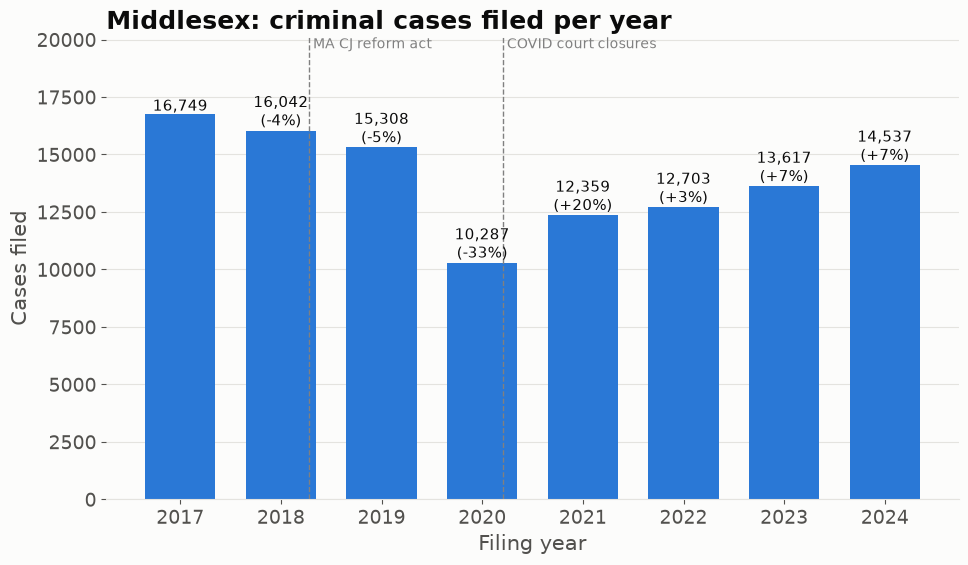

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017,16749,NaN,0.0
2018,16042,-4.2,-4.2
2019,15308,-4.6,-8.6
2020,10287,-32.8,-38.6
2021,12359,20.1,-26.2
2022,12703,2.8,-24.2
2023,13617,7.2,-18.7
2024,14537,6.8,-13.2


In [12]:
plot_volume(vol, COUNTY, f"{FIG_DIR}/{COUNTY}_q1_volume.png")

**How this was calculated**
- **Unit:** cases (one Case Number per defendant)
- **Source:** full extract, so open cases are counted
- **Date field:** Earliest Event Date (first court event); the extract has no filing date
- **Filters:** 2017 to 2024; Motor Vehicle Other cases and civil charges excluded

**Answer:** Middlesex had **14,537 cases in 2024, 13% fewer than in 2017 (16,749)**. Cases were already falling before COVID-19 (−9% by 2019), dropped 33% to 10,287 in 2020, and have grown every year since without returning to 2017 levels.

The 2024 count is one higher than in `questions.ipynb` because the one Case Number with two defendants is now split into two cases (the agreed docket × defendant unit).

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

,year,population,source
0,2017,1620034,Census 2010-2020 intercensal estimates (cc-est...
1,2018,1625887,Census 2010-2020 intercensal estimates (cc-est...
2,2019,1630745,Census 2010-2020 intercensal estimates (cc-est...
3,2020,1627578,Census Vintage 2024 estimates (co-est2024-alld...
4,2021,1620553,Census Vintage 2024 estimates (co-est2024-alld...
5,2022,1629805,Census Vintage 2024 estimates (co-est2024-alld...
6,2023,1644932,Census Vintage 2024 estimates (co-est2024-alld...
7,2024,1668956,Census Vintage 2024 estimates (co-est2024-alld...


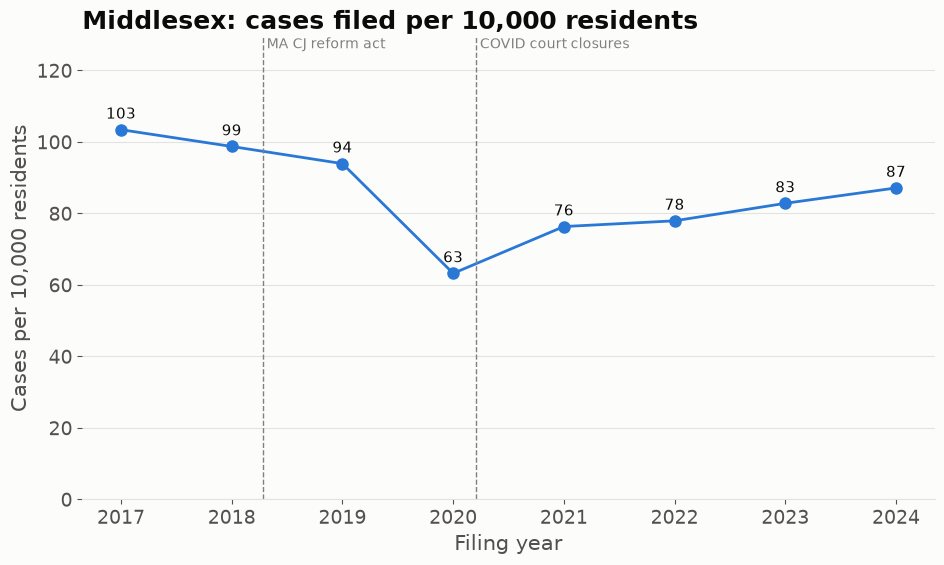

,cases_per_10k
filing_year,
2017,103.4
2018,98.7
2019,93.9
2020,63.2
2021,76.3
2022,77.9
2023,82.8
2024,87.1


In [13]:
pop = pd.read_csv(POP_PATH)
POPULATION = dict(zip(pop["year"], pop["population"]))   # Census July 1 estimates
display(pop)
plot_per_capita(vol, POPULATION, COUNTY, f"{FIG_DIR}/{COUNTY}_q2_per_capita.png")

**How this was calculated**
- **Numerator:** cases per year (from Q1)
- **Denominator:** Census Bureau July 1 estimates for Middlesex County, MA (`population.csv`). 2017–2019 from the [2010–2020 intercensal estimates](https://www2.census.gov/programs-surveys/popest/datasets/2010-2020/intercensal/county/asrh/); 2020–2024 from the [Vintage 2024 estimates](https://www2.census.gov/programs-surveys/popest/datasets/2020-2024/counties/totals/).

**Answer:** Middlesex had **87 cases per 10,000 residents in 2024**, down from 103 in 2017 (−16%). The rate fell slightly more than the case count (−13%) because the population grew 3%. It was lowest in 2020 (63) and has risen every year since.

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

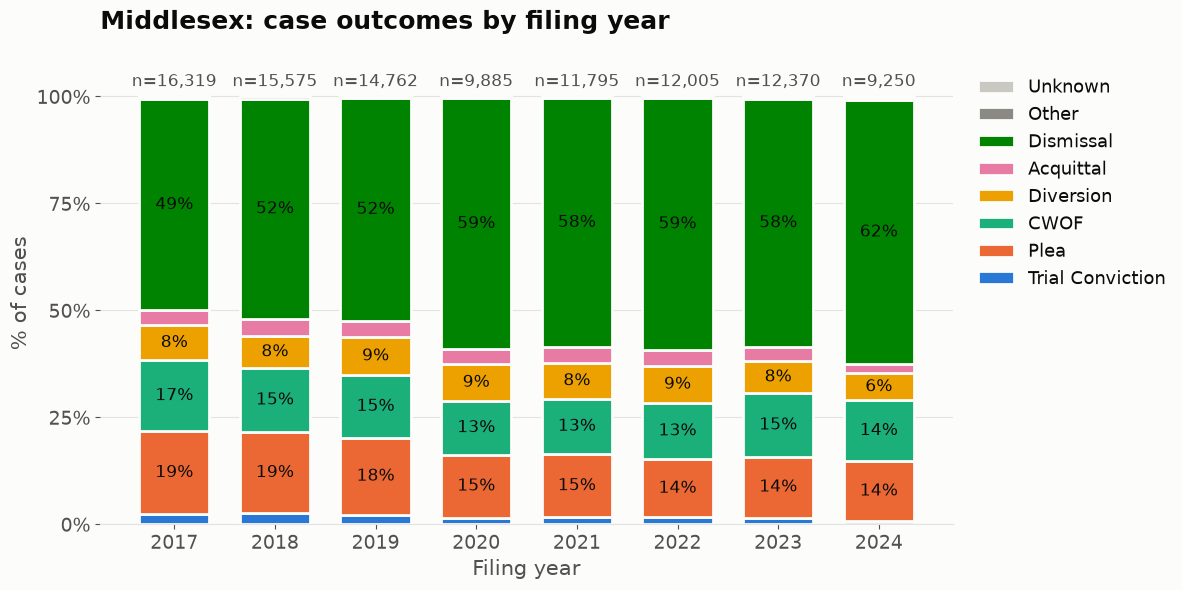

,cases,pct
outcome,,
Dismissal,56365,55.3
Plea,16652,16.3
CWOF,14724,14.4
Diversion,8202,8.0
Acquittal,3579,3.5
Trial Conviction,1914,1.9
Other,445,0.4
Unknown,80,0.1


outcome,Acquittal,CWOF,Dismissal,Diversion,Other,Plea,Trial Conviction,Unknown
year,,,,,,,,
2017,3.5,16.6,49.4,8.2,0.5,19.4,2.4,0.2
2018,3.9,15.0,51.5,7.5,0.5,18.9,2.6,0.0
2019,3.8,14.7,52.0,8.9,0.4,18.0,2.2,0.0
2020,3.5,12.5,58.6,8.6,0.4,14.8,1.5,0.0
2021,3.7,13.0,58.3,8.3,0.3,14.8,1.6,0.0
2022,3.8,13.3,58.9,8.5,0.3,13.6,1.6,0.0
2023,3.3,14.8,57.9,7.7,0.6,14.2,1.6,0.0
2024,2.2,14.2,61.8,6.3,0.5,14.0,0.7,0.3


In [14]:
overall, by_year_pct = plot_outcomes(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q3_outcomes_by_year.png")
display(overall, by_year_pct)

**How this was calculated**
- **Unit:** disposed criminal cases (one Case Number per defendant), pending cases excluded
- **Outcome rule:** most severe outcome across the case's charges
- **Date field:** year of Earliest Event Date
- **Mapping:** see `middlesex_outcome` and the full table above. Trial Conviction = guilty or delinquent at a jury or bench trial (incl. lesser included). Plea = guilty change of plea (incl. lesser offense), delinquent change of plea, guilty filed, guilty fines. CWOF = continued without a finding, incl. CWOF after trial. Diversion = pretrial probation, diversion, filed without change of plea. Acquittal = not guilty / not delinquent (trial, directed verdict, lack of criminal responsibility, insanity). Dismissal = every dismissal type (incl. dismissed on court costs, fines, community service or restitution), nolle prosequi, no bill, no probable cause. Other = transferred, remanded, bound over, hung jury, mistrial and other administrative results.

**Note:** cases still open or in default are Pending and excluded, and 2023 to 2024 have the most of them, so recent years lean toward fast-resolving cases.

**Answer:** Of 101,961 disposed cases, **55% were dismissed**, 8% went to diversion, 16% ended in a guilty plea and 14% in a CWOF. Only about 5% were decided at trial, and more of those ended in acquittal (3.5%) than conviction (1.9%).

**By year:** dismissals rose from 49% of disposed cases in 2017 to about 58–59% from 2020 on, while guilty pleas fell from 19% to 14% and trial convictions from 2.4% to 1.6%. 2024 (62% dismissed) is incomplete: about 36% of its cases are still pending.

Shares are slightly lower than in `questions.ipynb` because transferred and other unresolved cases now stay in the denominator as Other (0.4%), following the shared rule.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

Sentence type missing among convicted charges: 4.5%


charges
sentence      sentence_type                                              
Fines/Other   Continued Without  A Finding                            238
              Filed                                                  2739
              Fines                                                   257
Incarceration Combination Sentence DYS CMTD until 21 & Susp Sent       20
              Committed                                             11412
              DYS Committed Until Defendant 18                        146
              DYS Committed Until Defendant 19                          9
              DYS Committed Until Defendant 20                          2
              DYS Committed Until Defendant 21                         81
              Life With Parole                                         12
              Life Without Possibility of Parole                       12
              Split Sentence                                         2327
Probation     DYS Sentence Suspended Until Defendant 18                35
              DYS Sentence Suspended Until Defendant 21                22
              DYS Suspended                                            10
              Probation                                             14102
              Sentence Suspended                                     4442
Unknown       (blank)                                                1687

Missing sentence type: 4.8% of convicted cases


,cases,pct
sentence,,
Incarceration,6937,37.4
Probation,8796,47.4
Fines/Other,1935,10.4
Unknown,898,4.8


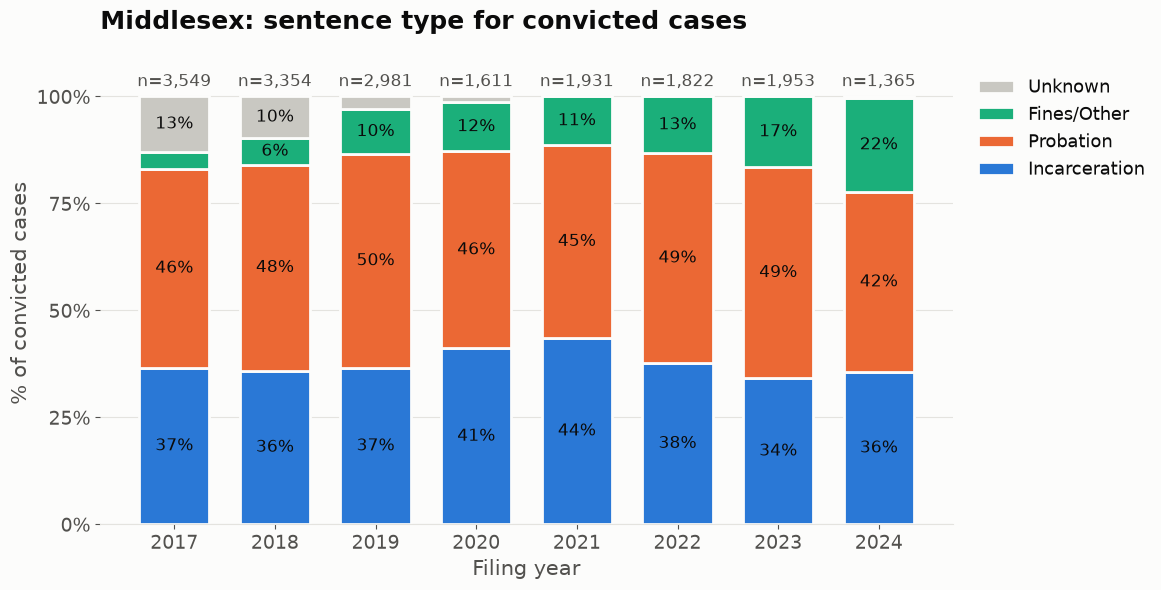

sentence,Incarceration,Probation,Fines/Other,Unknown
filing_year,,,,
2017,36.6,46.5,4.0,12.9
2018,35.9,48.1,6.3,9.7
2019,36.6,50.0,10.4,3.0
2020,41.1,46.1,11.5,1.3
2021,43.6,45.1,11.4,0.0
2022,37.7,49.0,13.3,0.0
2023,34.2,49.3,16.5,0.0
2024,35.6,42.1,22.1,0.3


In [15]:
SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

def classify_sentence(text):
    """Middlesex has a structured Sentence Type Imposed field."""
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"
    t = str(text)
    if any(k in t for k in ["Committed", "CMTD", "Life", "Split"]):   # jail/prison/DYS, split, life
        return "Incarceration"
    if any(k in t for k in ["Probation", "Suspended"]):
        return "Probation"
    return "Fines/Other"   # fines, filed, other

convicted_keys = cases.loc[cases["outcome"].isin(["Trial Conviction", "Plea"]), "case_key"]
conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                & disposed["case_key"].isin(convicted_keys)].copy()
conv_missing = conv["sentence_type"].isna().mean()
print(f"Sentence type missing among convicted charges: {conv_missing:.1%}")

if conv_missing > MISSING_THRESHOLD:
    print("Sentence type: insufficient data among convicted cases")
else:
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    display(conv.groupby(["sentence", conv["sentence_type"].fillna("(blank)")]).size()
                .rename("charges").to_frame())
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").groupby("case_key")
                     .agg(sentence=("sentence", "first"), filing_year=("filing_year", "first")))

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    ax = stacked_pct_bar(by_year, unit="convicted cases", xlabel="Filing year", colors=SENTENCE_COLORS,
                         title=f"{COUNTY.title()}: sentence type for convicted cases")
    save_fig(ax.figure, f"{FIG_DIR}/{COUNTY}_q4_sentencing.png")
    plt.show()
    display((by_year.div(by_year.sum(axis=1), axis=0) * 100).round(1))

**How this was calculated**
- **Unit:** convicted cases (Trial Conviction or Plea; CWOF is not a conviction)
- **Sentence rule:** most severe sentence across the case's convicted charges (Incarceration > Probation > Fines/Other)
- **Mapping:** `Sentence Type Imposed` is a structured field. Incarceration = Committed (jail, prison or DYS), Split Sentence, Life. Probation = Probation, Sentence Suspended (incl. DYS suspended). Fines/Other = Fines, Filed and any other value.
- **Missing:** blank sentence type is shown as Unknown (share printed above). Earlier years have more missing sentences.

**Answer:** Of 18,566 convicted cases, **37% resulted in incarceration**, 47% in probation (including suspended sentences), 10% in fines or other outcomes (mostly cases filed without a sentence), and 5% have no sentence recorded. Among convictions with a recorded sentence, incarceration is 39%.

**By year:** incarceration stayed between 34% and 44%, while fines/other grew from 4% of convictions in 2017 to 22% in 2024. Part of the early gap is missing data: 13% of 2017 and 10% of 2018 convictions have no sentence recorded.

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.

In [16]:
BAIL_PATH = None  # Middlesex extract has no bail data

if BAIL_PATH is None:
    jail_credit = filed["Jail Credit"].notna().mean()
    print("No bail data for this county: insufficient data")
    print(f"(closest field, Jail Credit, is filled for {jail_credit:.1%} of charges and only at sentencing)")

No bail data for this county: insufficient data
(closest field, Jail Credit, is filled for 1.3% of charges and only at sentencing)


**How this was calculated**

**Can't be answered with this data.** The Middlesex extract has no bail amount, bail type (cash or personal recognizance), detention status, or dangerousness-hearing fields.

The closest field, `Jail Credit` (days already served, credited at sentencing), is only recorded for people who were sentenced, so it can't show who was held before trial or whether bail was set. Answering this would need pretrial records from the courts, probation or the sheriff's office.

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

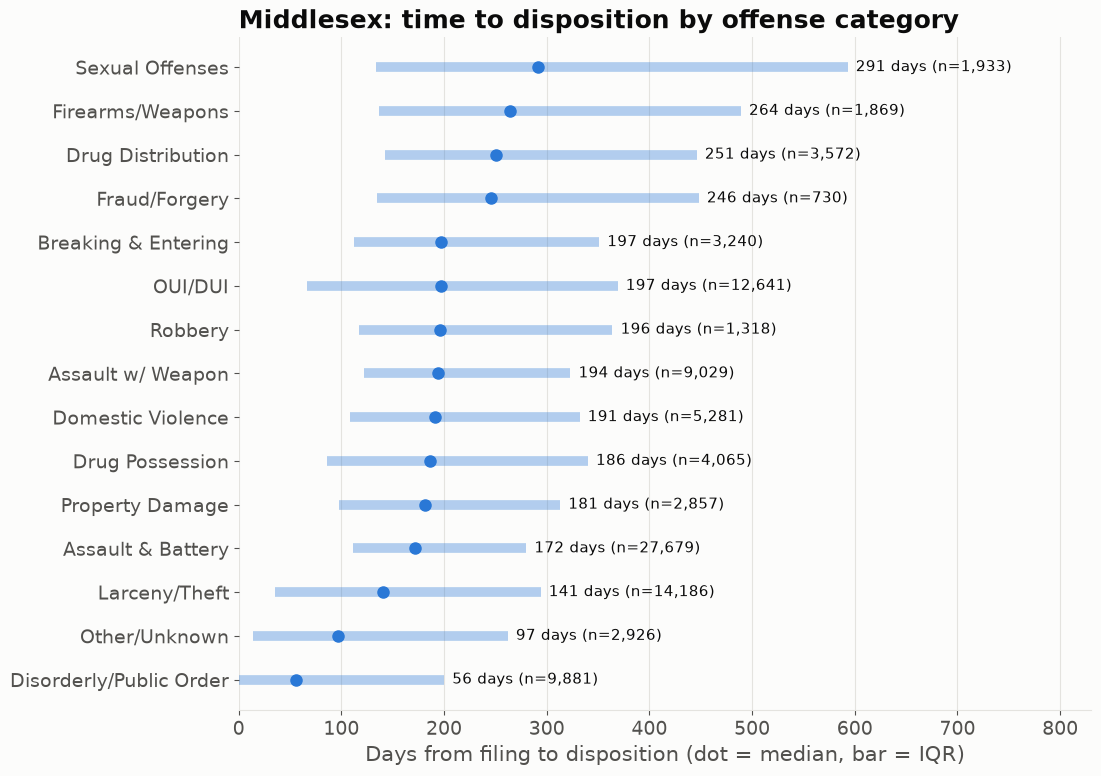

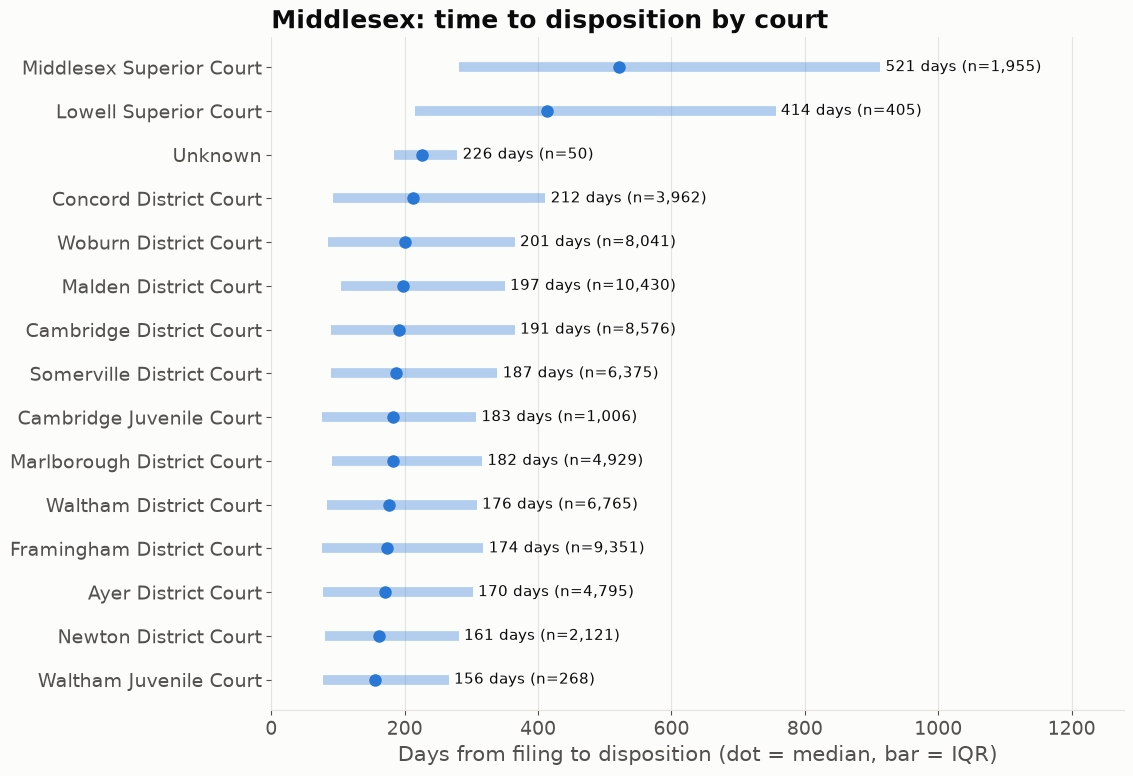

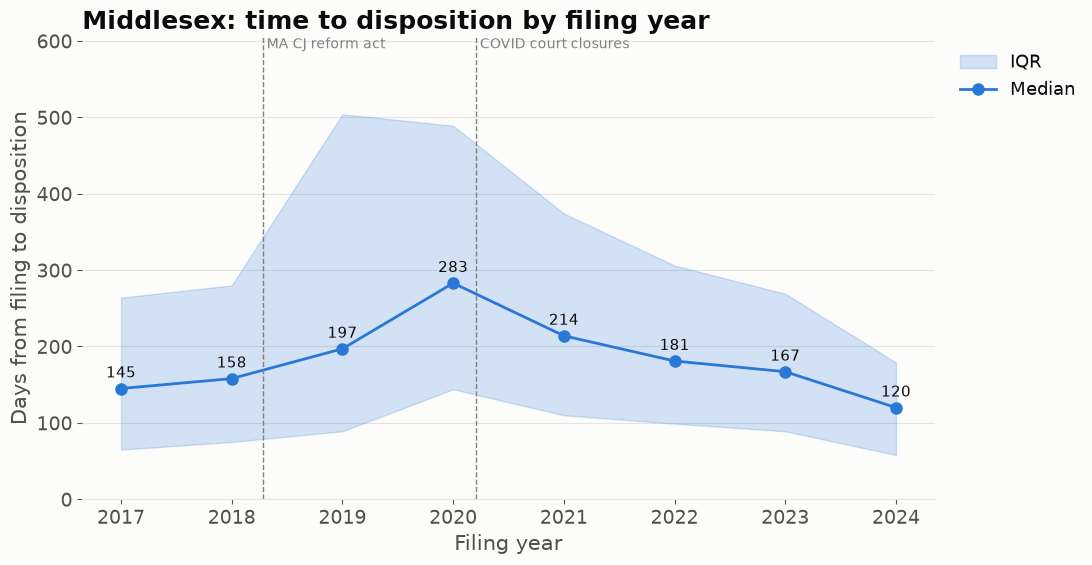

Overall median: 172 days (IQR 85-314)


,n,median,q1,q3
offense,,,,
Assault & Battery,27679,172.0,111.0,280.0
Assault w/ Weapon,9029,194.0,122.0,323.0
Breaking & Entering,3240,197.0,112.0,351.0
Disorderly/Public Order,9881,56.0,0.0,200.0
Domestic Violence,5281,191.0,108.0,332.0
Drug Distribution,3572,251.0,142.0,446.0
Drug Possession,4065,186.0,86.0,340.0
Firearms/Weapons,1869,264.0,137.0,489.0
Fraud/Forgery,730,246.0,135.0,448.0


,n,median,q1,q3
court,,,,
Ayer District Court,4795,170.0,77.0,302.0
Cambridge District Court,8576,191.0,89.0,365.0
Cambridge Juvenile Court,1006,183.0,76.0,307.0
Concord District Court,3962,212.0,93.0,411.0
Framingham District Court,9351,174.0,76.0,318.0
Framingham Juvenile Court,888,142.0,0.0,287.0
Lowell District Court,26971,145.0,80.0,234.0
Lowell Juvenile Court,1973,154.0,65.0,280.0
Lowell Superior Court,405,414.0,215.0,756.0


,n,median,q1,q3
year,,,,
2017,16140,145.0,65.0,264.0
2018,15460,158.0,75.0,280.0
2019,14680,197.0,89.0,504.0
2020,9813,283.0,144.0,489.0
2021,11707,214.0,110.0,374.0
2022,11950,181.0,99.0,306.0
2023,12294,167.0,89.0,269.0
2024,9163,120.0,58.0,179.0


In [17]:
t6_offense = plot_time(std, "offense", "offense category", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_offense.png")
t6_court = plot_time(std, "court", "court", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_court.png")
t6_year = plot_time_by_year(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_year.png")
print(f"Overall median: {std['days'].median():.0f} days "
      f"(IQR {std['days'].quantile(.25):.0f}-{std['days'].quantile(.75):.0f})")
display(t6_offense, t6_court, t6_year)

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** Earliest Event Date (no filing date in the extract) to the latest disposition date in the case
- **Filters:** pending cases, negative intervals and cases with an EDA date flag (offense after Earliest Event Date, or no event date) excluded; groups with fewer than 30 cases hidden
- **Charts:** by offense group, by court, and by year (dot or line = median, bar or band = IQR)

**Note:** pending cases are excluded, so 2023-24 medians are biased low.

**Answer:** The median disposed case took **172 days** (IQR 85–314) from the first court event to the last disposition. Disorderly/public order cases close fastest (median 56 days) and larceny in 141, while sexual offenses (291), firearms (264) and drug distribution (251) take longest. Superior Court cases take far longer (521 days in Middlesex Superior, 414 in Lowell Superior) than District Court cases (141–212).

**By year:** the median rose from 145 days for 2017 cases to 283 days for 2020 cases (the COVID-19 backlog), then fell back to 167 days by 2023. 2024's 120 days is low because its slower cases are still pending.

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

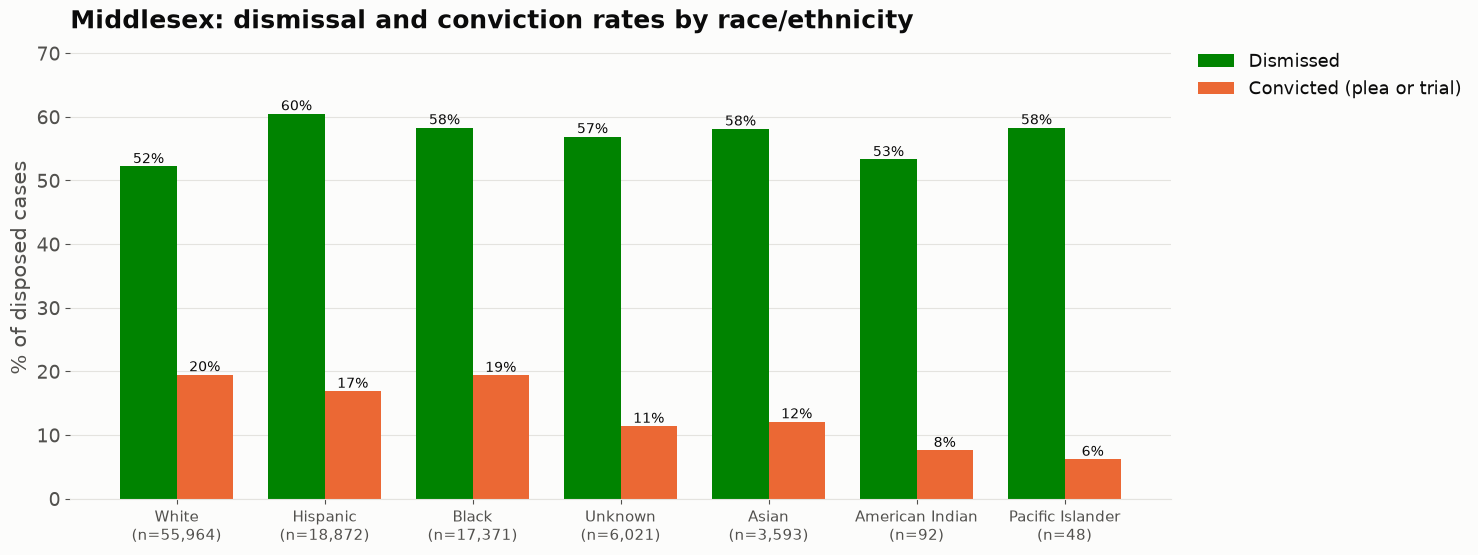

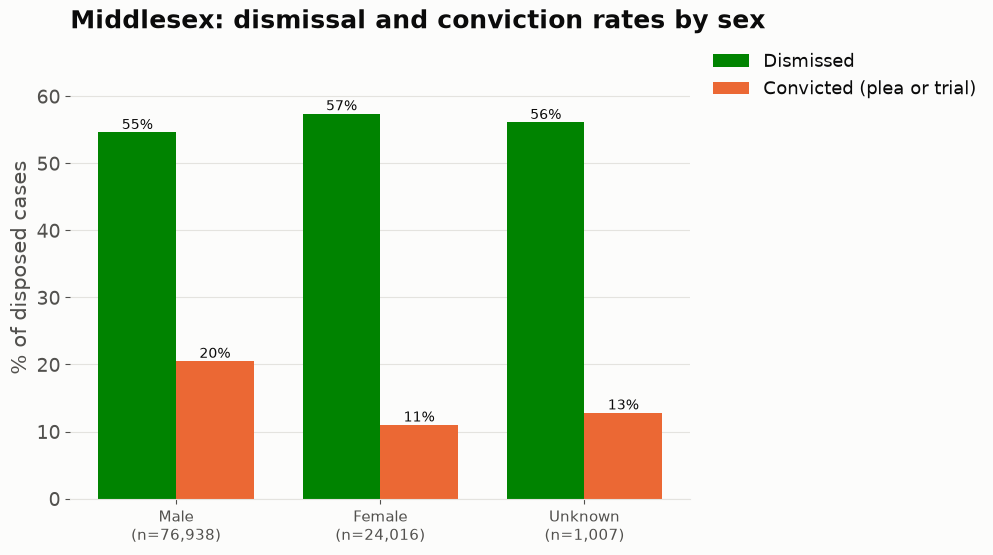

,n,dismissal_pct,dismissal_ratio_vs_White,conviction_pct,conviction_ratio_vs_White
race,,,,,
White,55964,52.2,1.00,19.5,1.00
Hispanic,18872,60.5,1.16,16.9,0.87
Black,17371,58.3,1.12,19.4,1.00
Unknown,6021,56.9,1.09,11.4,0.58
Asian,3593,58.1,1.11,12.1,0.62
American Indian,92,53.3,1.02,7.6,0.39
Pacific Islander,48,58.3,1.12,6.2,0.32


,n,dismissal_pct,dismissal_ratio_vs_Male,conviction_pct,conviction_ratio_vs_Male
sex,,,,,
Male,76938,54.6,1.00,20.5,1.00
Female,24016,57.4,1.05,11.0,0.54
Unknown,1007,56.1,1.03,12.8,0.62



Incarceration rate (convicted cases with a recorded sentence) by race


,n,incarceration_pct,ratio_vs_White
race,,,
White,10365,36.5,1.00
Black,3189,44.9,1.23
Hispanic,3075,44.3,1.22
Unknown,608,34.0,0.93
Asian,421,36.3,1.00



Incarceration rate (convicted cases with a recorded sentence) by sex


,n,incarceration_pct,ratio_vs_Male
sex,,,
Male,15082,41.9,1.00
Female,2477,23.9,0.57
Unknown,109,29.4,0.70


In [18]:
t7_race = plot_rates(std, "race", "White", "race/ethnicity", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_race.png")
t7_sex = plot_rates(std, "sex", "Male", "sex", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_sex.png")
display(t7_race, t7_sex)

# Incarceration among convicted cases (counties with sentence data)
if "case_sent" in globals():
    inc = case_sent.join(cases.set_index("case_key")[["race", "sex"]], how="inner")
    inc = inc[inc["sentence"].ne("Unknown")]            # convictions with a recorded sentence
    inc["incarcerated"] = inc["sentence"].eq("Incarceration")
    for group, ref in [("race", "White"), ("sex", "Male")]:
        g = inc.groupby(group)["incarcerated"].agg(n="size", rate="mean")
        g = g[g["n"] >= MIN_CELL]
        g["incarceration_pct"] = (g["rate"] * 100).round(1)
        g[f"ratio_vs_{ref}"] = (g["rate"] / g.loc[ref, "rate"]).round(2)
        print(f"\nIncarceration rate (convicted cases with a recorded sentence) by {group}")
        display(g.drop(columns="rate").sort_values("n", ascending=False))

**Middlesex supplement: race and ethnicity separately.** Because Hispanic/Latino is only recorded in the ethnicity field, and that field is often missing, the same rates are shown with race and ethnicity as separate fields. The Hispanic/Latino row here only covers cases where ethnicity was recorded.

In [19]:
lead_raw = (disposed.assign(cc=pd.to_numeric(disposed["charge_count"], errors="coerce"))
                    .sort_values(["case_key", "cc"]).drop_duplicates("case_key")
                    .set_index("case_key"))
ETHNICITY = {"Hispanic/Latino": "Hispanic/Latino", "Non-Hispanic/Non-Latino": "Not Hispanic/Latino"}
RACE_ONLY = {**RACE_MAP, "American Indian/Alaska Native": "Other", "Native Hawaiian/Pacific Islander": "Other",
             "Hispanic/Latino": "Other"}

sep = std.set_index("case_key")[["outcome", "dismissed"]].join(pd.DataFrame({
    "race (field only)": lead_raw["Defendant Race"].map(RACE_ONLY).fillna("Unknown"),
    "ethnicity": lead_raw["Defendant Ethnicity"].map(ETHNICITY).fillna("Unknown"),
}))
if "case_sent" in globals():
    sep = sep.join(case_sent["sentence"])

for field in ["race (field only)", "ethnicity"]:
    t = sep.groupby(field).agg(cases=("dismissed", "size"), dismissal_pct=("dismissed", "mean"))
    if "sentence" in sep:
        s = sep[sep["sentence"].notna() & sep["sentence"].ne("Unknown")]
        t["convictions_with_sentence"] = s.groupby(field).size()
        t["incarceration_pct"] = s["sentence"].eq("Incarceration").groupby(s[field]).mean()
    t[["dismissal_pct", "incarceration_pct"]] = (t[["dismissal_pct", "incarceration_pct"]] * 100).round(1)
    display(t[t["cases"] >= MIN_CELL].sort_values("cases", ascending=False))

,cases,dismissal_pct,convictions_with_sentence,incarceration_pct
race (field only),,,,
White,67526,53.5,12330,37.3
Black,18923,58.3,3515,45.9
Unknown,11435,59.9,1344,40.3
Asian,3616,58.2,422,36.3
Other,461,52.1,57,49.1


,cases,dismissal_pct,convictions_with_sentence,incarceration_pct
ethnicity,,,,
Not Hispanic/Latino,45387,54.1,9238,39.5
Unknown,37923,54.1,5388,36.0
Hispanic/Latino,18651,60.6,3042,44.2


**How this was calculated**
- **Unit:** disposed cases (dismissal, conviction); convicted cases with a recorded sentence (incarceration)
- **Race/ethnicity:** Hispanic if either the race or ethnicity field says Hispanic/Latino; otherwise the race field. Unknown kept as its own group.
- **Rates:** dismissal = Dismissal bucket; conviction = Plea or Trial Conviction (same in every county)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Filters:** groups under 30 cases suppressed

**Data gaps:** race is mostly missing in 2017, and the ethnicity field is "Not Provided" or blank for a large share of cases, so Hispanic is likely undercounted (those defendants fall back to their race, usually White). These are raw differences, not controlled for offense or prior record (that's Q8).

**Note:** Declination (cases the prosecutor declined to file) is not measurable in this extract.

**Answer:** Yes. Dismissal rates differ a little, conviction rates differ by sex, and incarceration rates differ by both race and sex.

- **Race/ethnicity:** Hispanic (60.5%) and Black (58.3%) defendants' cases were dismissed more often than White defendants' (52.2%). Conviction rates are the same for Black and White defendants (19%) and lower for Hispanic defendants (17%). But once convicted, Black (45%) and Hispanic (44%) defendants were incarcerated more often than White defendants (37%), about 1.2 times as often.
- **Sex:** dismissal rates are similar (men 55%, women 57%), but men were convicted almost twice as often (21% vs. 11%) and, when convicted, incarcerated far more often (42% vs. 24%).

The separate race / ethnicity table gives the same picture as `questions.ipynb`. These are raw gaps; Q8 checks them within the same offense and prior record.

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

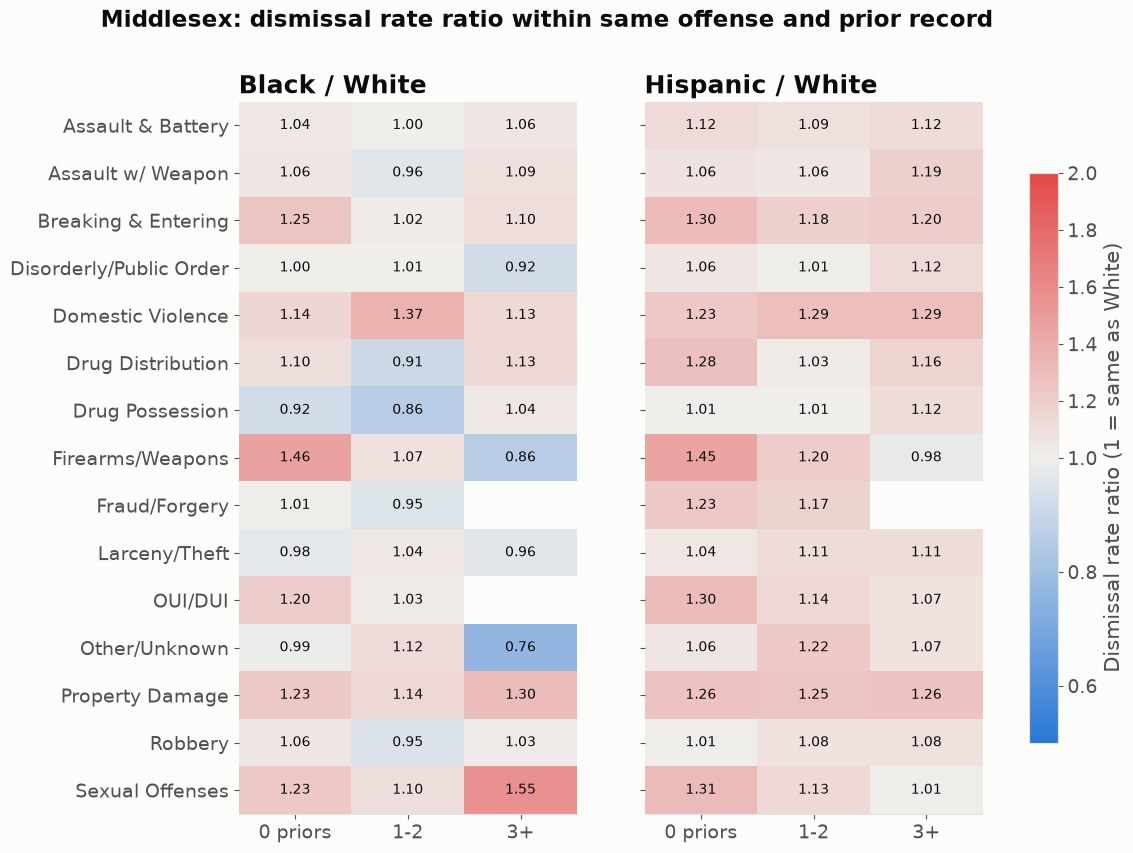

Q8 cases with known prior record: 101,960


race                                  Asian  Black  Hispanic  Unknown  White
offense                 prior_record                                        
Assault & Battery       0              69.9   68.5      73.7     66.4   65.7
                        1-2            73.1   65.8      71.9     67.0   66.0
                        3+             67.3   65.0      68.7      NaN   61.5
Assault w/ Weapon       0              63.2   66.0      66.2     58.8   62.2
                        1-2            58.7   58.9      64.6     71.9   61.1
                        3+              NaN   60.4      66.0      NaN   55.6
Breaking & Entering     0              54.2   50.2      52.3     50.6   40.2
                        1-2            60.0   42.7      49.5      NaN   41.8
                        3+              NaN   45.5      49.6      NaN   41.3
Disorderly/Public Order 0              74.4   69.2      73.4     85.4   69.4
                        1-2            73.0   69.6      70.0     60.4   69.2
                        3+             72.3   65.5      79.3      NaN   70.9
Domestic Violence       0              44.8   51.8      55.7     40.5   45.3
                        1-2            52.6   59.3      55.9     41.7   43.4
                        3+              NaN   53.6      61.2      NaN   47.6
Drug Distribution       0              61.3   52.6      61.3     51.6   48.0
                        1-2            32.5   38.0      43.1      NaN   41.9
                        3+              NaN   42.4      43.3      NaN   37.4
Drug Possession         0              52.1   50.7      55.7     50.0   54.9
                        1-2             NaN   45.9      53.7      NaN   53.4
                        3+              NaN   54.8      58.8      NaN   52.7
Firearms/Weapons        0              58.7   66.4      66.0     54.4   45.5
                        1-2             NaN   47.8      53.6      NaN   44.6
                        3+              NaN   38.7      43.9      NaN   44.9
Fraud/Forgery           0               NaN   38.9      47.3     39.7   38.4
                        1-2             NaN   54.3      66.7      NaN   57.0
                        3+              NaN    NaN       NaN      NaN   40.0
Larceny/Theft           0              58.2   55.2      59.1     57.6   56.6
                        1-2            51.8   56.2      59.7     44.3   53.8
                        3+             50.8   50.1      57.9      NaN   52.0
OUI/DUI                 0              13.7   16.8      18.2     15.8   14.0
                        1-2             NaN   24.1      26.8      NaN   23.5
                        3+              NaN    NaN      37.5      NaN   35.0
Other/Unknown           0              66.1   72.2      77.5     90.1   73.0
                        1-2             NaN   67.9      73.7      NaN   60.4
                        3+              NaN   54.1      76.1      NaN   71.0
Property Damage         0              58.3   57.5      59.0     56.8   46.8
                        1-2             NaN   58.1      64.0      NaN   51.0
                        3+              NaN   70.7      68.6      NaN   54.3
Robbery                 0               NaN   72.1      69.0     74.2   68.3
                        1-2             NaN   50.0      56.8      NaN   52.7
                        3+              NaN   56.9      60.0      NaN   55.3
Sexual Offenses         0              51.5   56.7      60.2     38.6   46.1
                        1-2             NaN   48.1      49.6      NaN   43.8
                        3+              NaN   59.4      38.7      NaN   38.2

prior_record,0,1-2,3+,Unknown
"year (share of cases by prior record, %)",,,,
2017,81.9,15.9,2.1,0.0
2018,68.0,24.1,7.9,0.0
2019,62.7,25.2,12.1,0.0
2020,61.9,24.3,13.8,0.0
2021,61.9,25.2,12.9,0.0
2022,62.3,24.6,13.0,0.0
2023,62.6,22.9,14.5,0.0
2024,61.6,22.5,15.9,0.0


In [20]:
if "defendant_id" in INSUFFICIENT:
    print("Q8: insufficient data (defendant ID over 20% missing)")
else:
    q8_rates = plot_q8_heatmap(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q8_dismissal_ratio_heatmap.png")
    display(q8_rates)
    display(pd.crosstab(std["year"], std["prior_record"], normalize="index").mul(100).round(1)
              .rename_axis(index="year (share of cases by prior record, %)"))

**How this was calculated**
- **Unit:** disposed cases with a known prior record
- **Prior record:** the defendant's cases (same Defendant ID) in the 3 years before this case (same lookback in every county), bucketed 0 / 1-2 / 3+
- **Cells:** offense group × prior record × race; cells under 30 cases suppressed
- **Heatmap value:** group dismissal rate / White dismissal rate in the same cell (1.00 = no gap; blue = lower, red = higher)

**Limitations (Middlesex):**
- History starts in 2017, so cases in 2017 to 2019 don't have a full 3-year lookback and their prior record is undercounted (see the table above: the 0-prior share is highest in early years).
- Only Middlesex cases are counted, not statewide history.
- It counts earlier cases, not convictions.
- Motor Vehicle Other cases were filtered out, so they don't count toward prior record.

**Answer:** Mostly yes. Within the same offense group and prior-record level, **Hispanic defendants' cases were dismissed more often than White defendants' in almost every cell** (most ratios between 1.0 and 1.3). **Black defendants are closer to parity** (most cells between 0.9 and 1.15), with higher ratios for sexual offenses with 3+ priors (1.55), firearms with no priors (1.46) and domestic violence with 1–2 priors (1.37), and lower ratios for drug possession (0.86–0.92). So the raw dismissal gaps in Q7 are not explained by offense or prior record alone.

The incarceration supplement below gives the same result as `questions.ipynb`: about half of the Black–White incarceration gap (45% vs. 37%) comes from offense mix (41% at the White mix). The rest is concentrated in domestic violence, firearms, assault & battery and drug possession. That comparison doesn't control for prior record.

Prior record for 2017–2019 cases is undercounted because the history starts in 2017.

### Middlesex supplement: incarceration gap within offense group
Convicted Black and White defendants compared within the same offense group, and the Black incarceration rate re-weighted to the White offense mix. This doesn't control for prior record.

In [21]:
if "case_sent" in globals():
    pair = (case_sent.join(std.set_index("case_key")[["race", "offense"]], how="inner")
                     .query("race in ['White', 'Black'] and sentence != 'Unknown'")
                     .assign(incarcerated=lambda d: d["sentence"].eq("Incarceration")))
    r = pair.groupby(["offense", "race"])["incarcerated"].agg(["mean", "size"]).unstack("race")

    white_mix = pair[pair["race"].eq("White")]["offense"].value_counts(normalize=True)
    black_rates = r["mean"]["Black"][r["size"]["Black"] >= MIN_CELL].dropna()
    common = white_mix.index.intersection(black_rates.index)
    same_mix = (black_rates[common] * white_mix[common]).sum() / white_mix[common].sum()
    raw_rate = pair.groupby("race")["incarcerated"].mean()
    print(f"Incarcerated, raw: White {raw_rate['White']:.1%}, Black {raw_rate['Black']:.1%}")
    print(f"Black, at the White offense mix: {same_mix:.1%}")

    q8_sup = pd.DataFrame({
        "White convictions": r["size"]["White"], "Black convictions": r["size"]["Black"],
        "White % incarcerated": (r["mean"]["White"] * 100).round(1),
        "Black % incarcerated": (r["mean"]["Black"] * 100).round(1),
    })
    q8_sup = q8_sup[(q8_sup["White convictions"] >= MIN_CELL) & (q8_sup["Black convictions"] >= MIN_CELL)]
    q8_sup["gap (points)"] = (q8_sup["Black % incarcerated"] - q8_sup["White % incarcerated"]).round(1)
    display(q8_sup.sort_values("gap (points)", ascending=False))

Incarcerated, raw: White 36.5%, Black 44.9%
Black, at the White offense mix: 40.5%


,White convictions,Black convictions,White % incarcerated,Black % incarcerated,gap (points)
offense,,,,,
Other/Unknown,247,100,50.6,71.0,20.4
Domestic Violence,750,136,34.3,52.9,18.6
Firearms/Weapons,217,144,58.1,75.7,17.6
Assault & Battery,1652,583,38.0,48.9,10.9
Drug Possession,558,114,30.8,39.5,8.7
Assault w/ Weapon,694,303,50.6,57.1,6.5
Sexual Offenses,329,80,42.9,47.5,4.6
Breaking & Entering,650,192,52.0,53.6,1.6
Drug Distribution,468,207,49.4,49.8,0.4


## Cross-County Comparison View (District Courts Only)
Plymouth's Superior Court records stop after 2020, so the Plymouth analysis covers district courts only. This view restricts Middlesex to its District Courts (Superior and Juvenile Courts excluded) so counties can be compared on the same court scope.

Use these numbers on any slide that compares counties. The full-county results above remain the main Middlesex answers.

District-only: 95,327 disposed cases (93.5% of all)


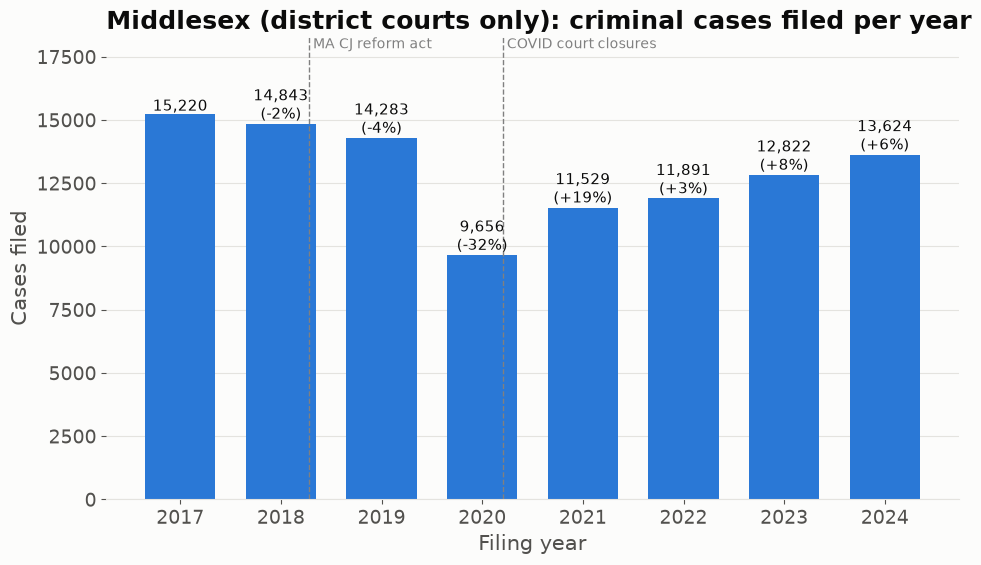

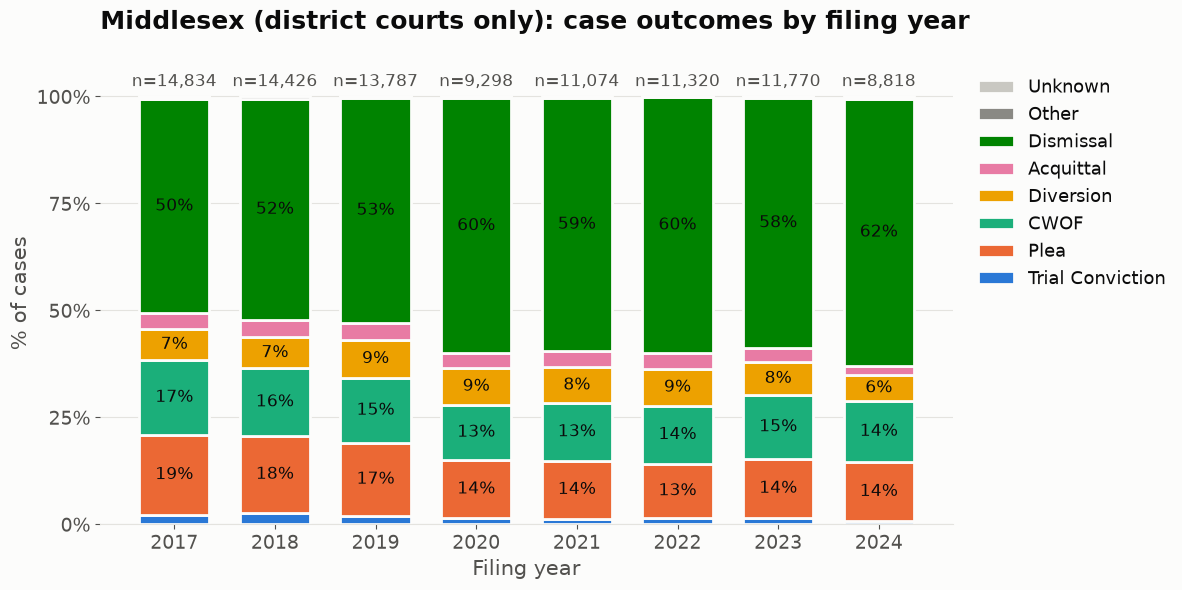

,cases,pct
outcome,,
Dismissal,53402,56.0
Plea,14782,15.5
CWOF,14206,14.9
Diversion,7486,7.9
Acquittal,3406,3.6
Trial Conviction,1663,1.7
Other,317,0.3
Unknown,65,0.1


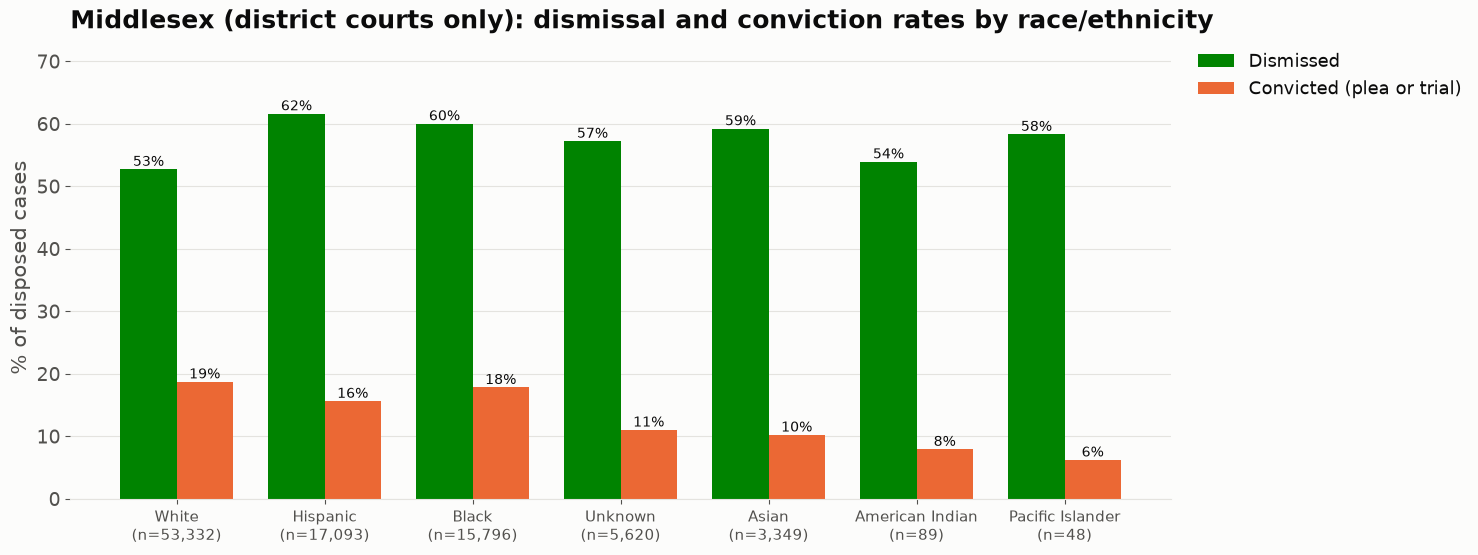

,n,dismissal_pct,dismissal_ratio_vs_White,conviction_pct,conviction_ratio_vs_White
race,,,,,
White,53332,52.7,1.00,18.7,1.00
Hispanic,17093,61.6,1.17,15.6,0.83
Black,15796,60.0,1.14,17.8,0.95
Unknown,5620,57.2,1.08,11.0,0.59
Asian,3349,59.2,1.12,10.2,0.55
American Indian,89,53.9,1.02,7.9,0.42
Pacific Islander,48,58.3,1.11,6.2,0.33


In [22]:
is_district = lambda s: s.astype(str).str.contains("District Court", case=False)
std_d = std[is_district(std["court"])]
vol_d = filed_cases[is_district(filed_cases["court"])].groupby("filing_year").size()
vol_d.index = vol_d.index.astype(int)
print(f"District-only: {len(std_d):,} disposed cases ({len(std_d) / len(std):.1%} of all)")

scope = "district courts only"
plot_volume(vol_d, COUNTY, f"{FIG_DIR}/{COUNTY}_compare_q1_volume_district.png", scope=scope)
overall_d, _ = plot_outcomes(std_d, COUNTY, f"{FIG_DIR}/{COUNTY}_compare_q3_outcomes_district.png", scope=scope)
display(overall_d)
display(plot_rates(std_d, "race", "White", "race/ethnicity", COUNTY,
                   f"{FIG_DIR}/{COUNTY}_compare_q7_rates_by_race_district.png", scope=scope))

**How this was calculated**
- Same definitions as the sections above, restricted to cases whose lead charge was in a District Court (including Natick District Court @ Framingham)
- Superior and Juvenile Court cases are excluded to match Plymouth's court coverage

## Questions for the Client
- Is a filing date available? Earliest Event Date is used in its place.
- Is a felony/misdemeanor (or statutory class) field available? Cases are classified by lead charge.
- Why is ethnicity "Not Provided" or blank for so many defendants, and can it be filled in? Hispanic defendants are likely undercounted.
- Is bail or pretrial detention data available? Q5 can't be answered without it.
- Is a statewide prior-record field, or history before 2017, available? Prior record here only counts Middlesex cases from 2017 on.
- Can declined referrals be provided? Declination isn't measurable in this extract.